# A3. 평론 점수 vs 한국 유저 평가

**담당:** 이고은 · **데이터:** 2026-11-25 mariadb-re, 본편 게임 916개 (games + game_review_stats + 장르 + 동접)

## 한 줄 결론
> 평론 점수만 보고 사면 한국 유저 평가와 어긋난다. 특히 **2021년 이후 게임**은 평론이 유저보다 후하고, 한국 유저는 전 세계 평균보다 **3.7%p 박하다.**

## 가설
1. 평론 점수가 높은 게임은 한국 유저 평가도 높다.
2. 장르와 출시 시기에 따라 평론과 유저가 갈린다.
3. 한국 유저는 전 세계 유저와 평가가 다르다.
4. 평론 점수만으로 유저 평가를 맞힐 수 없지만, 다른 요소를 더하면 나아진다.

**쓰는 말:** 평론 = IGDB `aggregated_rating` / 유저 = Steam 한국어 리뷰 긍정 % / **괴리(gap) = 유저 − 평론** (+이면 유저가 더 후함)

In [1]:
import json, os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from scipy import stats

# 한글 글꼴: 있는 것 중 첫 번째를 쓴다 (Windows·Mac·Linux 공통)
for f in ("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc", "/usr/share/fonts/opentype/noto/NotoSansCJK-Bold.ttc"):
    if Path(f).exists():
        font_manager.fontManager.addfont(f)
have = {f.name for f in font_manager.fontManager.ttflist}
for name in ("Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"):
    if name in have:
        plt.rcParams["font.family"] = name
        break
plt.rcParams.update({"axes.unicode_minus": False, "font.size": 12, "axes.edgecolor": "#c9c8c3",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a3a29d"
INK, MUTED, GRID, BG = "#0b0b0b", "#52514e", "#e8e7e3", "#fcfcfb"
DATA = Path(os.environ.get("GAMENURI_DATA_DIR", "../data"))   # 노트북은 analysis/notebooks 에서 연다


def frame(ax, grid="both"):
    """차트 바탕: 옅은 격자, 위·오른쪽 테두리 제거"""
    ax.set_facecolor(BG)
    ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

## 1. 데이터 불러오기

In [2]:
d = pd.read_csv(DATA / "a3_games.tsv", sep="\t", na_values=["NULL"])
d["year"] = pd.to_datetime(d.release_date, errors="coerce").dt.year

MIN_CRITICS = 3   # 평론이 3개 이상 모인 게임만 쓴다 (1~2개는 점수가 흔들린다)
a = d[(d.aggregated_rating > 0) & (d.aggregated_rating_count >= MIN_CRITICS)].copy()
a["gap"] = a.positive_pct_ko - a.aggregated_rating     # + 면 유저가 더 후함

print(f"전체 게임 {len(d)}개 → 평론 {MIN_CRITICS}개 이상인 게임 {len(a)}개를 분석에 쓴다")
d[["name", "release_date", "aggregated_rating", "aggregated_rating_count", "positive_pct_ko", "positive_pct_all"]].head()

전체 게임 916개 → 평론 3개 이상인 게임 571개를 분석에 쓴다


,name,release_date,aggregated_rating,aggregated_rating_count,positive_pct_ko,positive_pct_all
0,BioShock,2007-08-21,92.62,8.0,92,93
1,Dead Space 2,2011-01-25,90.00,8.0,93,94
2,The Elder Scrolls IV: Oblivion,2006-03-20,80.57,6.0,77,94
3,Portal 2,2011-04-18,92.44,9.0,98,98
4,L.A. Noire,2011-05-17,89.38,7.0,74,85


## 2. 평론과 한국 유저 평가는 같이 움직이나

순위상관 0.35 (p = 3.8e-18, 게임 571개)


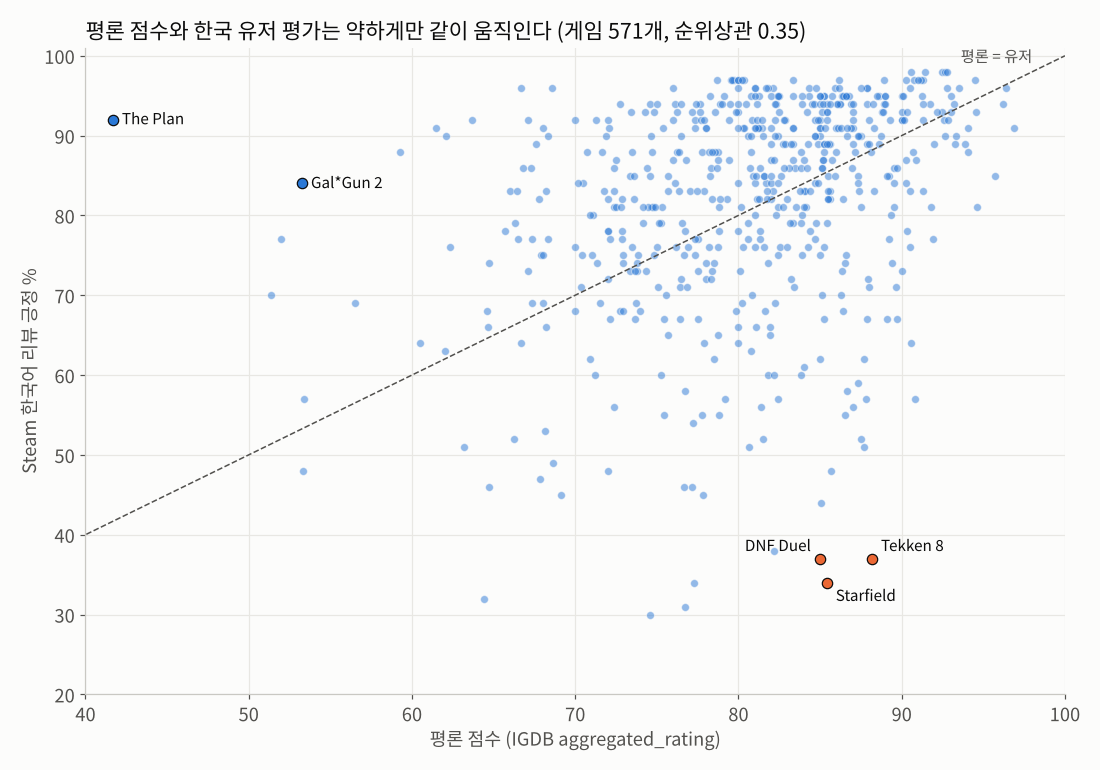

In [3]:
rho, p = stats.spearmanr(a.aggregated_rating, a.positive_pct_ko)
print(f"순위상관 {rho:.2f} (p = {p:.1e}, 게임 {len(a)}개)")

fig, ax = plt.subplots(figsize=(10, 7), facecolor=BG)
frame(ax)
ax.plot([0, 100], [0, 100], color=MUTED, lw=1, ls="--")
ax.text(98, 99, "평론 = 유저", color=MUTED, ha="right", va="bottom", fontsize=10)
ax.scatter(a.aggregated_rating, a.positive_pct_ko, s=26, color=BLUE, alpha=0.5, edgecolor=BG, lw=0.6)

# 괴리가 가장 큰 게임 이름표 (유저가 더 후한 3개, 평론이 더 후한 3개)
LABEL_POS = [(6, -3, "left")] * 3 + [(6, -12, "left"), (6, 5, "left"), (-6, 5, "right")]
for j, (_, r) in enumerate(pd.concat([a.nlargest(3, "gap"), a.nsmallest(3, "gap")]).iterrows()):
    ax.scatter(r.aggregated_rating, r.positive_pct_ko, s=46, color=BLUE if r.gap > 0 else ORANGE, edgecolor=INK, lw=0.8, zorder=3)
    dx, dy, ha = LABEL_POS[j]
    ax.annotate(r["name"], (r.aggregated_rating, r.positive_pct_ko), xytext=(dx, dy), textcoords="offset points", fontsize=10, color=INK, ha=ha)

ax.set_xlim(40, 100); ax.set_ylim(20, 101)
ax.set_xlabel("평론 점수 (IGDB aggregated_rating)")
ax.set_ylabel("Steam 한국어 리뷰 긍정 %")
ax.set_title(f"평론 점수와 한국 유저 평가는 약하게만 같이 움직인다 (게임 {len(a)}개, 순위상관 {rho:.2f})", loc="left", fontsize=14, color=INK)
plt.tight_layout(); plt.show()

**의미 판단:** 순위상관이 0.35로 양(+)의 관계는 있지만 약하다. 평론이 높아도 한국 유저 평가는 크게 흩어져 있다. 점선 아래(주황)에 있는 게임이 "평론만 믿으면 실망하는" 게임이다.

## 3. 장르마다 평론과 유저가 갈린다

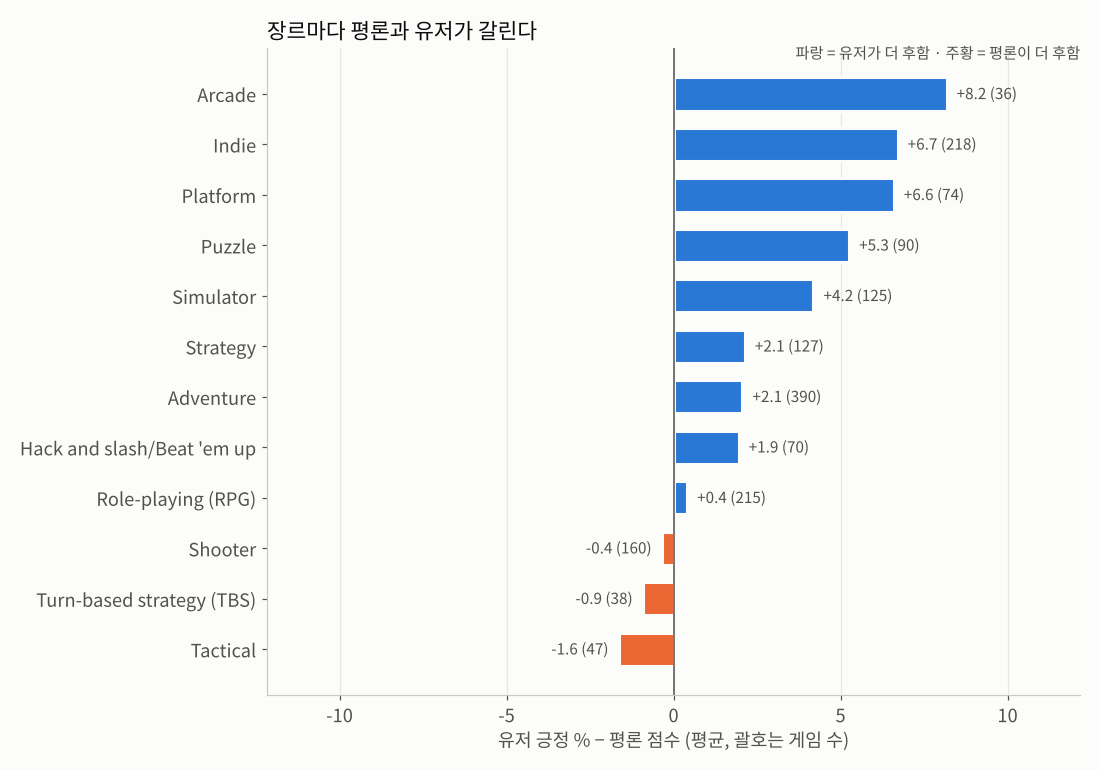

In [4]:
MIN_GENRE = 30
g = a.assign(genre=a.genres.str.split("|")).explode("genre")
t = (g.groupby("genre").agg(n=("gap", "size"), gap=("gap", "mean"))
       .query("n >= @MIN_GENRE").sort_values("gap"))

fig, ax = plt.subplots(figsize=(10, 7), facecolor=BG)
frame(ax, "x")
ax.barh(t.index, t.gap, color=[BLUE if v >= 0 else ORANGE for v in t.gap], height=0.66, edgecolor=BG, lw=2)
ax.axvline(0, color=MUTED, lw=1)
for i, (v, k) in enumerate(zip(t.gap, t.n, strict=True)):
    ax.text(v + (0.3 if v >= 0 else -0.3), i, f"{v:+.1f} ({k})", va="center", ha="left" if v >= 0 else "right", fontsize=10, color=MUTED)
lim = max(abs(t.gap.min()), abs(t.gap.max())) + 4
ax.set_xlim(-lim, lim)
ax.set_xlabel("유저 긍정 % − 평론 점수 (평균, 괄호는 게임 수)")
ax.set_title("장르마다 평론과 유저가 갈린다", loc="left", fontsize=14, color=INK)
ax.text(lim, len(t) - 0.3, "파랑 = 유저가 더 후함 · 주황 = 평론이 더 후함", ha="right", fontsize=10, color=MUTED)
plt.tight_layout(); plt.show()

**의미 판단:** 아케이드·인디·플랫포머는 유저가 평론보다 6~8점 후하고, 전술·턴제 전략·슈터는 평론이 더 후하다. 같은 평론 점수라도 장르에 따라 유저 평가가 다르다.

## 4. 출시 시기: 2021년 이후 뒤집힌다

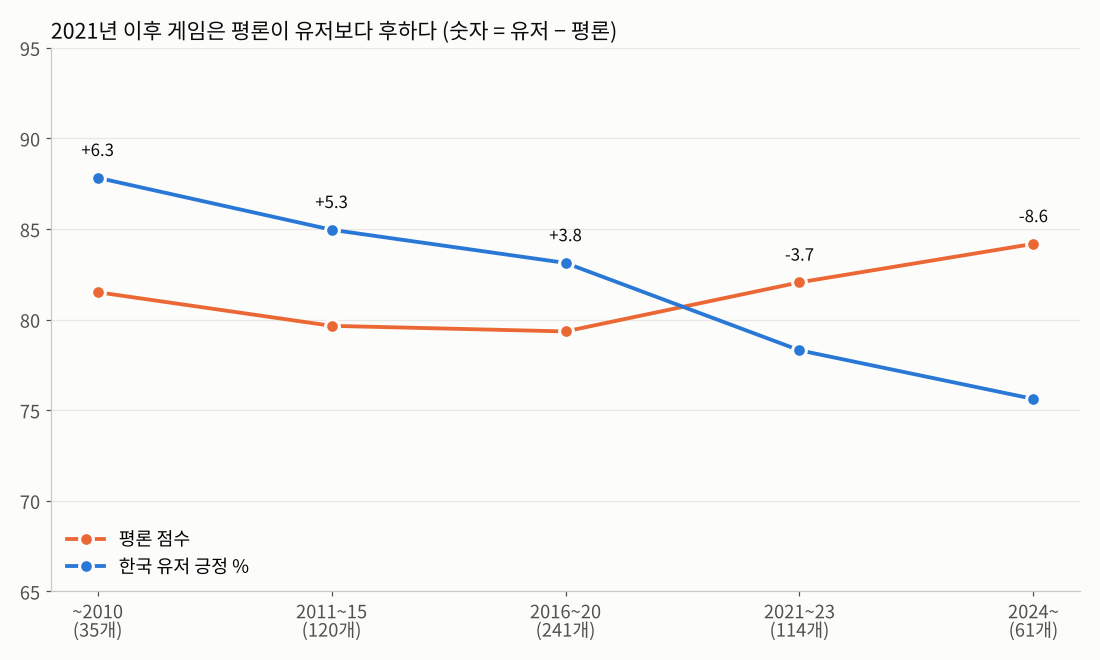

,n,critic,user
year,,,
~2010,35,81.5,87.8
2011~15,120,79.7,85.0
2016~20,241,79.3,83.1
2021~23,114,82.1,78.3
2024~,61,84.2,75.6


In [5]:
bins = [1980, 2010, 2015, 2020, 2023, 2030]
labels = ["~2010", "2011~15", "2016~20", "2021~23", "2024~"]
y = a.groupby(pd.cut(a.year, bins, labels=labels), observed=False).agg(
    n=("gap", "size"), critic=("aggregated_rating", "mean"), user=("positive_pct_ko", "mean"))

fig, ax = plt.subplots(figsize=(10, 6), facecolor=BG)
frame(ax, "y")
x = np.arange(len(y))
ax.plot(x, y.critic, color=ORANGE, lw=2.5, marker="o", ms=9, mec=BG, mew=2, label="평론 점수")
ax.plot(x, y.user, color=BLUE, lw=2.5, marker="o", ms=9, mec=BG, mew=2, label="한국 유저 긍정 %")
for i, r in enumerate(y.itertuples()):
    ax.text(i, max(r.critic, r.user) + 1.2, f"{r.user - r.critic:+.1f}", ha="center", fontsize=11, color=INK)
ax.set_xticks(x, [f"{lab}\n({k}개)" for lab, k in zip(labels, y.n, strict=True)])
ax.set_ylim(65, 95)
ax.legend(frameon=False, loc="lower left")
ax.set_title("2021년 이후 게임은 평론이 유저보다 후하다 (숫자 = 유저 − 평론)", loc="left", fontsize=14, color=INK)
plt.tight_layout(); plt.show()
y.round(1)

**의미 판단:** 2020년까지는 유저가 평론보다 4~6점 높았는데, 2021~23년은 −3.7, 2024년 이후는 −8.6으로 뒤집힌다. 최신작은 평론 점수만 보고 사면 실망할 수 있다. (출시 직후 버그·가격 불만이 리뷰에 몰리는 영향일 수 있다 → A4)

## 5. 한국 유저는 전 세계 평균보다 박하다

전체 평균 -3.65%p, 한국이 더 박한 게임 70%, 윌콕슨 부호순위검정 p = 2.8e-67


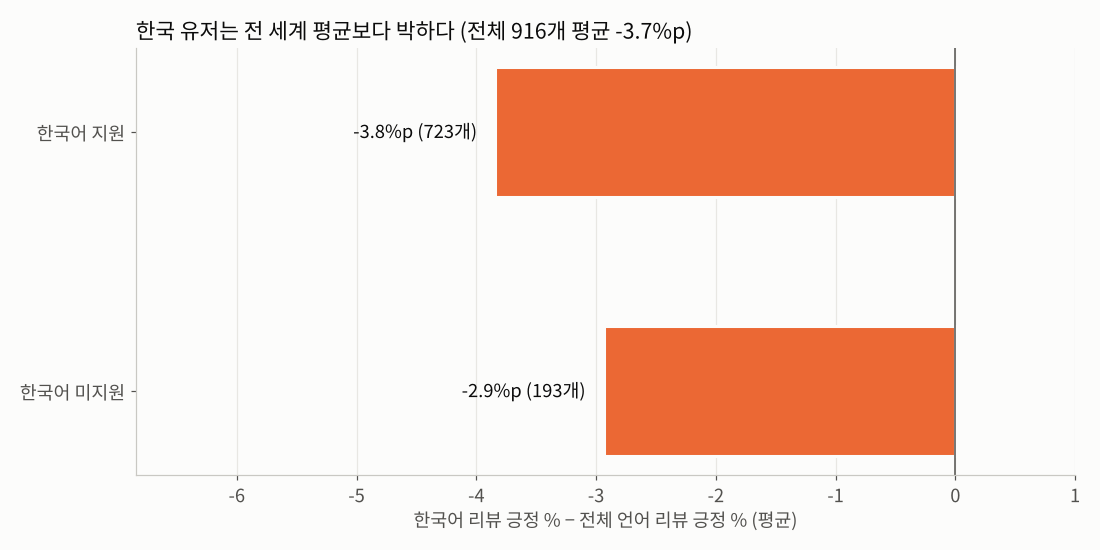

In [6]:
d["kgap"] = d.positive_pct_ko - d.positive_pct_all      # 한국어 리뷰 긍정 % − 전체 언어 리뷰 긍정 %
k = d.groupby("korean_supported").kgap.agg(["size", "mean", "median"])
w = stats.wilcoxon(d.kgap.dropna())
print(f"전체 평균 {d.kgap.mean():+.2f}%p, 한국이 더 박한 게임 {(d.kgap < 0).mean():.0%}, 윌콕슨 부호순위검정 p = {w.pvalue:.1e}")

fig, ax = plt.subplots(figsize=(10, 5), facecolor=BG)
frame(ax, "x")
names = {0: "한국어 미지원", 1: "한국어 지원"}
rows = [(names[i], r["mean"], int(r["size"])) for i, r in k.iterrows()]
ax.barh([r[0] for r in rows], [r[1] for r in rows], color=ORANGE, height=0.5, edgecolor=BG, lw=2)
for i, (_, v, cnt) in enumerate(rows):
    ax.text(v - 0.15, i, f"{v:+.1f}%p ({cnt}개)", va="center", ha="right", fontsize=12, color=INK)
ax.axvline(0, color=MUTED, lw=1)
ax.set_xlim(min(r[1] for r in rows) - 3, 1)
ax.set_xlabel("한국어 리뷰 긍정 % − 전체 언어 리뷰 긍정 % (평균)")
ax.set_title(f"한국 유저는 전 세계 평균보다 박하다 (전체 {len(d)}개 평균 {d.kgap.mean():+.1f}%p)", loc="left", fontsize=14, color=INK)
plt.tight_layout(); plt.show()

**의미 판단:** 게임의 약 70%에서 한국 유저가 더 박하게 평가한다. 평균 차이는 −3.7%p이고 통계적으로 0이 아니다. 한국어를 지원해도 차이가 줄지 않는다(지원 −3.8, 미지원 −2.9). 번역 때문만은 아니라는 뜻이다.

## 6. 평론 점수만으로 유저 평가를 맞힐 수 있나 (예측 모델)

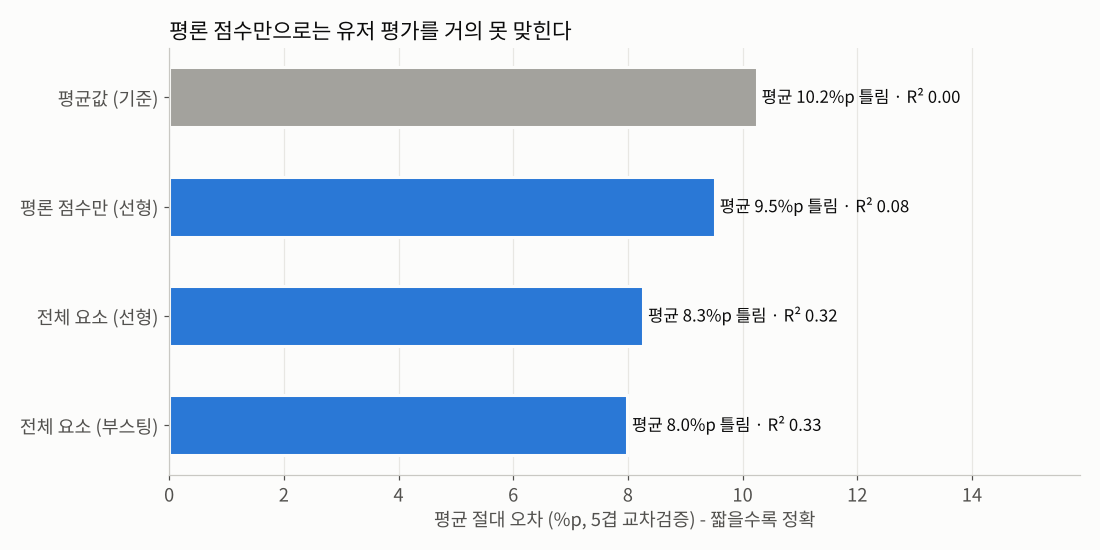

,mae,r2
평균값 (기준),10.25,0.000
평론 점수만 (선형),9.52,0.082
전체 요소 (선형),8.27,0.316
전체 요소 (부스팅),7.99,0.328


In [7]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict

SEED = 42
top_genres = g.genre.value_counts().loc[lambda s: s >= MIN_GENRE].index.tolist()
X = pd.DataFrame({
    "평론 점수": a.aggregated_rating, "평론 수": a.aggregated_rating_count,
    "출시 연도": a.year.fillna(a.year.median()), "온라인": a.is_online,
    "한국어 지원": a.korean_supported, "연령 등급": a.age_rating,
    "최대 동접(log)": np.log10(a.peak_players.clip(lower=1)),
    "한국어 리뷰 수(log)": np.log10(a.review_count_ko.clip(lower=1)),
}, index=a.index)
for gname in top_genres:
    X[f"장르:{gname}"] = a.genres.str.split("|").apply(lambda s, gn=gname: int(gn in s))
yv = a.positive_pct_ko.values

cv = KFold(5, shuffle=True, random_state=SEED)
models = {
    "평균값 (기준)": None,
    "평론 점수만 (선형)": ("one", LinearRegression()),
    "전체 요소 (선형)": ("all", LinearRegression()),
    "전체 요소 (부스팅)": ("all", GradientBoostingRegressor(random_state=SEED, max_depth=3, n_estimators=300, learning_rate=0.03, subsample=0.8)),
}
res, preds = {}, {}
for name, spec in models.items():
    if spec is None:
        p = np.full_like(yv, yv.mean(), dtype=float)
    else:
        cols, m = spec
        p = cross_val_predict(m, X[["평론 점수"]] if cols == "one" else X, yv, cv=cv)
    preds[name] = p
    res[name] = {"mae": round(float(np.mean(np.abs(yv - p))), 2),
                 "r2": round(float(1 - np.sum((yv - p) ** 2) / np.sum((yv - yv.mean()) ** 2)), 3)}

fig, ax = plt.subplots(figsize=(10, 5), facecolor=BG)
frame(ax, "x")
names_m = list(res); maes = [res[m]["mae"] for m in names_m]
ax.barh(names_m[::-1], maes[::-1], color=[GRAY, BLUE, BLUE, BLUE][::-1], height=0.55, edgecolor=BG, lw=2)
for i, m in enumerate(names_m[::-1]):
    ax.text(res[m]["mae"] + 0.08, i, f"평균 {res[m]['mae']:.1f}%p 틀림 · R² {res[m]['r2']:.2f}", va="center", fontsize=11, color=INK)
ax.set_xlim(0, max(maes) * 1.55)
ax.set_xlabel("평균 절대 오차 (%p, 5겹 교차검증) - 짧을수록 정확")
ax.set_title("평론 점수만으로는 유저 평가를 거의 못 맞힌다", loc="left", fontsize=14, color=INK)
plt.tight_layout(); plt.show()
pd.DataFrame(res).T

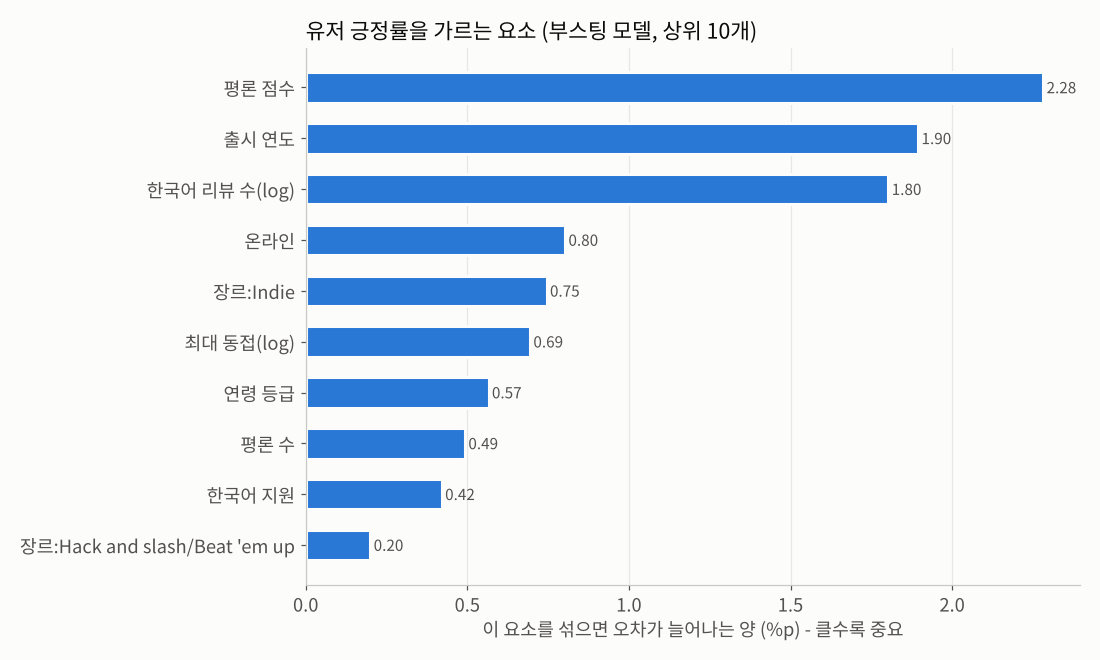

In [8]:
gb = models["전체 요소 (부스팅)"][1].fit(X, yv)
pi = permutation_importance(gb, X, yv, n_repeats=20, random_state=SEED, scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6), facecolor=BG)
frame(ax, "x")
imp_r = imp[::-1]
ax.barh(imp_r.index, imp_r.values, color=BLUE, height=0.6, edgecolor=BG, lw=2)
for i, v in enumerate(imp_r.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=10, color=MUTED)
ax.set_xlabel("이 요소를 섞으면 오차가 늘어나는 양 (%p) - 클수록 중요")
ax.set_title("유저 긍정률을 가르는 요소 (부스팅 모델, 상위 10개)", loc="left", fontsize=14, color=INK)
plt.tight_layout(); plt.show()

**의미 판단:** 평론 점수만으로는 평균 9.5%p 틀리고(R² 0.08), 출시 연도·리뷰 수·온라인·장르를 더하면 8.0%p(R² 0.33)로 줄어든다. 그래도 오차가 크므로 **정확한 점수 예측이 아니라 "위험 신호" 수준**으로 쓴다. 영향이 큰 요소는 평론 점수 > 출시 연도 > 한국어 리뷰 수 > 온라인 > 인디 장르 순이다.

## 7. 숨은 명작과 과대평가 후보

In [9]:
a["pred"] = preds["전체 요소 (부스팅)"]
cols = ["name", "year", "aggregated_rating", "positive_pct_ko", "gap", "genres"]
print("유저가 훨씬 후함 (숨은 명작 후보)")
display_hi = a.nlargest(8, "gap")[cols].round(1)
display_hi

유저가 훨씬 후함 (숨은 명작 후보)


,name,year,aggregated_rating,positive_pct_ko,gap,genres
238,The Plan,2013,41.7,92,50.3,Adventure|Indie
122,7 Days to Die,2024,36.1,86,49.9,Adventure|Indie|Role-playing (RPG)|Shooter|Simulator|Strategy
455,Gal*Gun 2,2018,53.2,84,30.8,Adventure|Arcade|Shooter
376,House Flipper,2018,61.5,91,29.5,Indie|Simulator
479,Muse Dash,2018,66.7,96,29.3,Indie|Music
100,Postal 2,2003,59.2,88,28.8,Adventure|Indie|Shooter
124,Assetto Corsa,2014,63.7,92,28.3,Indie|Racing|Simulator|Sport
261,Rain World,2017,62.1,90,27.9,Adventure|Indie|Platform


In [10]:
print("평론이 훨씬 후함 (과대평가 후보)")
a.nsmallest(8, "gap")[cols].round(1)

평론이 훨씬 후함 (과대평가 후보)


,name,year,aggregated_rating,positive_pct_ko,gap,genres
493,Starfield,2023,85.4,34,-51.4,Adventure|Role-playing (RPG)|Shooter
800,Tekken 8,2024,88.2,37,-51.2,Fighting
680,DNF Duel,2022,85.0,37,-48.0,Fighting|Strategy
295,"Warhammer 40,000: Dawn of War III",2017,76.7,31,-45.7,Real Time Strategy (RTS)|Simulator|Strategy
837,Little Nightmares III,2025,74.6,30,-44.6,Adventure|Platform|Puzzle
867,Sid Meier's Civilization VII,2025,82.2,38,-44.2,Simulator|Strategy|Tactical|Turn-based strategy (TBS)
909,EA Sports FC 26,2025,77.2,34,-43.2,Simulator|Sport
629,Assassin's Creed Valhalla,2020,85.1,44,-41.1,Adventure|Role-playing (RPG)


## 8. 수익 연결: 메일 속 제휴 추천과 광고 배너

한국어 미지원인데 한국어 리뷰가 1,000건 이상인 게임: 42개 (전체 916개 중)


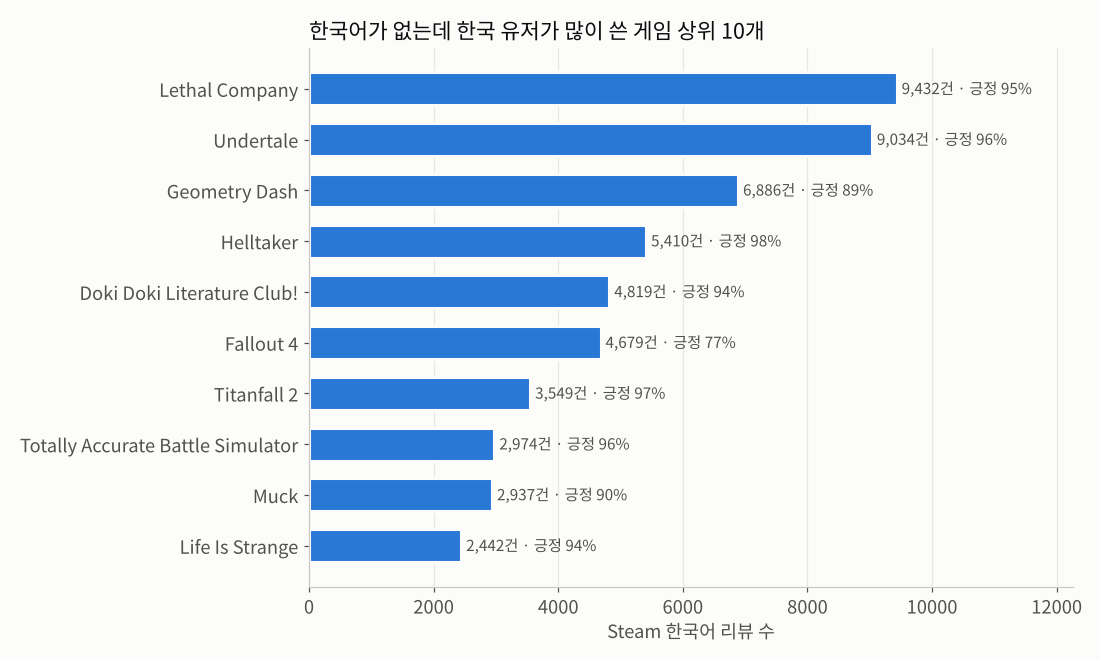

,name,review_count_ko,positive_pct_ko,positive_pct_all
0,Lethal Company,9432,95,96
1,Undertale,9034,96,96
2,Geometry Dash,6886,89,93
3,Helltaker,5410,98,97
4,Doki Doki Literature Club!,4819,94,96
5,Fallout 4,4679,77,81
6,Titanfall 2,3549,97,95
7,Totally Accurate Battle Simulator,2974,96,97
8,Muck,2937,90,93
9,Life Is Strange,2442,94,96


In [11]:
demand = d[(d.korean_supported == 0) & (d.review_count_ko >= 1000)].sort_values("review_count_ko", ascending=False)
print(f"한국어 미지원인데 한국어 리뷰가 1,000건 이상인 게임: {len(demand)}개 (전체 {len(d)}개 중)")

top = demand.head(10)
fig, ax = plt.subplots(figsize=(10, 6), facecolor=BG)
frame(ax, "x")
ax.barh(top.name[::-1], top.review_count_ko[::-1], color=BLUE, height=0.65, edgecolor=BG, lw=2)
for i, (v, pct) in enumerate(zip(top.review_count_ko[::-1], top.positive_pct_ko[::-1], strict=True)):
    ax.text(v + 80, i, f"{v:,}건 · 긍정 {pct:.0f}%", va="center", fontsize=10, color=MUTED)
ax.set_xlim(0, top.review_count_ko.max() * 1.3)
ax.set_xlabel("Steam 한국어 리뷰 수")
ax.set_title("한국어가 없는데 한국 유저가 많이 쓴 게임 상위 10개", loc="left", fontsize=14, color=INK)
plt.tight_layout(); plt.show()
top[["name", "review_count_ko", "positive_pct_ko", "positive_pct_all"]].reset_index(drop=True)

## 인사이트와 활용

| 인사이트 | 서비스·수익에 쓰는 법 |
|---|---|
| 평론과 한국 유저 평가는 약하게만 일치, 장르·시기에 따라 갈림 | 게임 상세에 "평론보다 유저 평가가 높은/낮은 게임" 꼬리표. 최신작은 유저 리뷰(A4 불만 유형)를 같이 보여 준다 |
| 한국 유저는 평균 3.7%p 박함 | 글로벌 평점을 그대로 보여 주지 않고 한국어 리뷰 평점을 따로 보여 준다 |
| 한국어 미지원인데 한국 리뷰가 많은 게임 42개 | "한글화를 기다리는 게임" 순위 페이지에 **광고 배너**를 두고, 메일 속 **제휴 추천** 게임을 고를 때 한국 수요가 큰 게임을 우선한다 |

## 한계
- 평론은 IGDB `aggregated_rating`이고 평론 3개 이상 게임(571개)만 쓴다.
- 예측 오차가 약 8%p라 정확한 점수가 아니라 위험 신호로 쓴다.
- 한국어 지원 여부는 수집 시점(11/25)의 Steam 표기 기준이다.
- 상관과 중요도는 "같이 나타난다"이지 원인이 아니다. 매출 금액은 추정하지 않는다.